## Embeddings, Attention, and Transformer Mathematics

### Learning Goals
* Understand how token embeddings map discrete items into dense vector spaces ($\mathbb{R}^d$).
* Implement scaled dot-product attention using queries ($Q$), keys ($K$), and values ($V$).
* Analyze self-attention weight matrices and recognize the architectural limits of raw attention scores.

---

### 1. Token Embeddings and Attention

An embedding maps discrete tokens or data points to continuous numerical vectors:
$$
\text{token} \longrightarrow x \in \mathbb{R}^d
$$

**Scaled Dot-Product Attention** computes contextual representations by weighting value vectors according to query-key alignment:
$$
\operatorname{Attention}(Q, K, V) = \operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right) V
$$
where $d_k$ is the dimensionality of the key vectors, preventing gradient saturation in high dimensions.

Attention Weights Matrix:
[[0.455 0.162 0.382]
 [0.068 0.848 0.085]
 [0.408 0.217 0.375]]

Row Sums (Check = 1.0): [1. 1. 1.]

Contextual Output Vectors:
[[-0.184 -1.011  0.699  0.674]
 [-1.635 -1.246  0.233 -0.139]
 [-0.305 -1.027  0.664  0.607]]


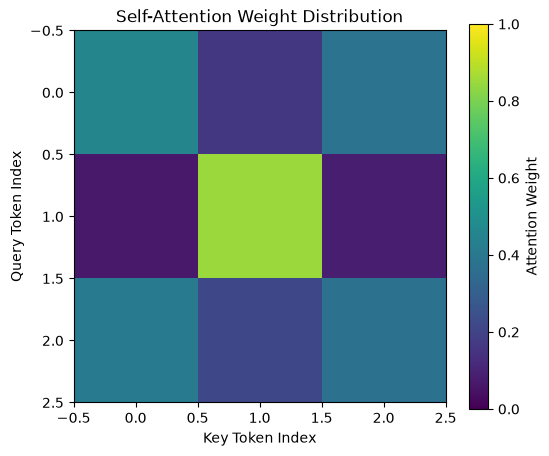

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def softmax(x, axis=-1):
    shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

rng = np.random.default_rng(42)
embeddings = rng.normal(size=(3, 4))  # 3 tokens, 4 dimensions

Q = embeddings
K = embeddings
V = embeddings

scores = Q @ K.T / np.sqrt(K.shape[1])
attention_weights = softmax(scores, axis=1)
contextual_vectors = attention_weights @ V

print("Attention Weights Matrix:")
print(np.round(attention_weights, 3))
print("\nRow Sums (Check = 1.0):", np.round(attention_weights.sum(axis=1), 4))
print("\nContextual Output Vectors:")
print(np.round(contextual_vectors, 3))

plt.figure(figsize=(6, 5))
plt.imshow(attention_weights, cmap='viridis', vmin=0, vmax=1)
plt.colorbar(label="Attention Weight")
plt.xlabel("Key Token Index")
plt.ylabel("Query Token Index")
plt.title("Self-Attention Weight Distribution")
plt.show()

### 2. What Attention Does and Does Not Show

Each query generates a probability distribution over keys, combining value vectors into a rich contextual representation. 

> **Important Limitation:** Raw attention weights alone do not constitute a complete explanation of a model's downstream decisions; modern transformer architectures rely on multi-head projections, layer normalization, residual connections, and deep feed-forward layers.

---

### Exercises

Try each problem before running the verification code below:

1. Verify that every row of the computed attention matrix sums to exactly $1.0$.
2. Change the random seed or embedding dimensions and observe the resulting attention distribution.
3. Explain the distinct operational roles of Queries ($Q$), Keys ($K$), and Values ($V$).
4. Why should attention weights not be interpreted naively as faithful explanations of model reasoning?

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print(f"\n1. Row Sum Verification:")
print(f"   - Sums: {attention_weights.sum(axis=1)} (Validated as 1.0 via Softmax normalization)")

print("\n2. Changing Seeds/Embeddings:")
print("   - Altering input embeddings modifies dot-product scores, shifting the softmax distribution")
print("     to concentrate attention on different token pairs based on vector alignment.")

print("\n3. Roles of Q, K, and V:")
print("   - Queries (Q): What the token is looking for.")
print("   - Keys (K): What information the token contains to match queries.")
print("   - Values (V): The actual content transferred when a match occurs.")

print("\n4. Attention Weights as Explanations:")
print("   - Attention weights only show token-to-token routing scores in a single layer,")
print("     ignoring how subsequent feed-forward layers and multiple attention heads transform representations.")

=== Exercise Solutions & Checks ===

1. Row Sum Verification:
   - Sums: [1. 1. 1.] (Validated as 1.0 via Softmax normalization)

2. Changing Seeds/Embeddings:
   - Altering input embeddings modifies dot-product scores, shifting the softmax distribution
     to concentrate attention on different token pairs based on vector alignment.

3. Roles of Q, K, and V:
   - Queries (Q): What the token is looking for.
   - Keys (K): What information the token contains to match queries.
   - Values (V): The actual content transferred when a match occurs.

4. Attention Weights as Explanations:
   - Attention weights only show token-to-token routing scores in a single layer,
     ignoring how subsequent feed-forward layers and multiple attention heads transform representations.
